In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

In [2]:
data = np.load("spectrum_sensing_dataset.npz")

X_iq = data["X"]
y = data["y"]
snr = data["snr"]

print("Dataset shape:", X_iq.shape)
print("Labels shape:", y.shape)
print("SNR values:", np.unique(snr))

Dataset shape: (14000, 256)
Labels shape: (14000,)
SNR values: [-20 -15 -10  -5   0   5  10]


In [3]:
def generate_noise(n_samples, noise_power):
    noise = np.sqrt(noise_power / 2) * (
        np.random.randn(n_samples)
        + 1j * np.random.randn(n_samples)
    )
    return noise


def generate_uncertain_dataset(
    snr_values,
    uncertainty_db,
    n_windows=1000,
    window_length=256
):
    X = []
    y = []
    snr_labels = []

    for snr_db in snr_values:

        # Nominal noise power for this SNR condition
        nominal_noise_power = 1 / (10 ** (snr_db / 10))

        for label in [0, 1]:

            for _ in range(n_windows):

                # Random noise-power variation
                epsilon = np.random.uniform(
                    -uncertainty_db,
                    uncertainty_db
                )

                actual_noise_power = (
                    nominal_noise_power
                    * 10 ** (epsilon / 10)
                )

                noise = generate_noise(
                    window_length,
                    actual_noise_power
                )

                if label == 0:
                    received_signal = noise

                else:
                    # Unit-power QPSK signal
                    i = np.random.choice([-1, 1], window_length)
                    q = np.random.choice([-1, 1], window_length)

                    signal = (i + 1j * q) / np.sqrt(2)

                    received_signal = signal + noise

                X.append(received_signal)
                y.append(label)
                snr_labels.append(snr_db)

    return (
        np.array(X),
        np.array(y),
        np.array(snr_labels)
    )

In [4]:
snr_values = np.array([-20, -15, -10, -5, 0, 5, 10])

uncertainty_levels = [0, 1, 2, 3]

uncertainty_datasets = {}

for uncertainty in uncertainty_levels:

    X_unc, y_unc, snr_unc = generate_uncertain_dataset(
        snr_values=snr_values,
        uncertainty_db=uncertainty,
        n_windows=1000,
        window_length=256
    )

    uncertainty_datasets[uncertainty] = {
        "X": X_unc,
        "y": y_unc,
        "snr": snr_unc
    }

    print(f"\nUncertainty: {uncertainty} dB")
    print("Dataset shape:", X_unc.shape)
    print("H0 samples:", np.sum(y_unc == 0))
    print("H1 samples:", np.sum(y_unc == 1))


Uncertainty: 0 dB
Dataset shape: (14000, 256)
H0 samples: 7000
H1 samples: 7000

Uncertainty: 1 dB
Dataset shape: (14000, 256)
H0 samples: 7000
H1 samples: 7000

Uncertainty: 2 dB
Dataset shape: (14000, 256)
H0 samples: 7000
H1 samples: 7000

Uncertainty: 3 dB
Dataset shape: (14000, 256)
H0 samples: 7000
H1 samples: 7000


In [5]:
for uncertainty, dataset in uncertainty_datasets.items():

    np.savez_compressed(
        f"noise_uncertainty_{uncertainty}dB.npz",
        X=dataset["X"],
        y=dataset["y"],
        snr=dataset["snr"]
    )

print("All uncertainty datasets saved successfully.")

All uncertainty datasets saved successfully.


In [6]:
from sklearn.model_selection import train_test_split

# Use nominal dataset (0 dB uncertainty)
X_nominal = uncertainty_datasets[0]["X"]
y_nominal = uncertainty_datasets[0]["y"]
snr_nominal = uncertainty_datasets[0]["snr"]

# Reproduce the stratified 70/15/15 split
indices = np.arange(len(y_nominal))

groups = np.array([
    f"{label}_{s}"
    for label, s in zip(y_nominal, snr_nominal)
])

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=groups
)

temp_groups = groups[temp_idx]

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=temp_groups
)

# Calculate nominal validation energies
energy_nominal = np.mean(
    np.abs(X_nominal) ** 2,
    axis=1
)

# Calibrate thresholds using H0 validation samples
energy_thresholds_nominal = {}

for s in snr_values:
    mask = (snr_nominal[val_idx] == s) & (
        y_nominal[val_idx] == 0
    )

    threshold = np.quantile(
        energy_nominal[val_idx][mask],
        0.95,
        method="higher"
    )

    energy_thresholds_nominal[s] = threshold

print("Nominal Energy Detection thresholds:")
for s, threshold in energy_thresholds_nominal.items():
    print(f"SNR {s:>3} dB: {threshold:.6f}")

Nominal Energy Detection thresholds:
SNR -20 dB: 111.016965
SNR -15 dB: 34.708617
SNR -10 dB: 10.823495
SNR  -5 dB: 3.480406
SNR   0 dB: 1.097970
SNR   5 dB: 0.348696
SNR  10 dB: 0.108967


In [7]:
uncertainty_results = []

for uncertainty in uncertainty_levels:

    X_unc = uncertainty_datasets[uncertainty]["X"]
    y_unc = uncertainty_datasets[uncertainty]["y"]
    snr_unc = uncertainty_datasets[uncertainty]["snr"]

    # Use the same test indices
    X_test_unc = X_unc[test_idx]
    y_test_unc = y_unc[test_idx]
    snr_test_unc = snr_unc[test_idx]

    # Calculate received energy
    energy_test_unc = np.mean(
        np.abs(X_test_unc) ** 2,
        axis=1
    )

    # Apply fixed nominal thresholds
    y_pred_unc = np.zeros(len(y_test_unc), dtype=int)

    for i, s in enumerate(snr_test_unc):
        y_pred_unc[i] = int(
            energy_test_unc[i] > energy_thresholds_nominal[s]
        )

    # Overall confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test_unc,
        y_pred_unc,
        labels=[0, 1]
    ).ravel()

    pd_value = tp / (tp + fn)
    pfa_value = fp / (fp + tn)
    pm_value = fn / (fn + tp)
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    uncertainty_results.append({
        "Uncertainty_dB": uncertainty,
        "Accuracy": accuracy,
        "Pd": pd_value,
        "Pfa": pfa_value,
        "Pm": pm_value
    })

uncertainty_df = pd.DataFrame(uncertainty_results)

print(uncertainty_df.round(4))

   Uncertainty_dB  Accuracy      Pd     Pfa      Pm
0               0    0.8019  0.6705  0.0667  0.3295
1               1    0.7105  0.7219  0.3010  0.2781
2               2    0.6700  0.7210  0.3810  0.2790
3               3    0.6524  0.7352  0.4305  0.2648


In [8]:
uncertainty_df.to_csv(
    "energy_detection_noise_uncertainty.csv",
    index=False
)

print("Energy Detection uncertainty results saved.")

Energy Detection uncertainty results saved.


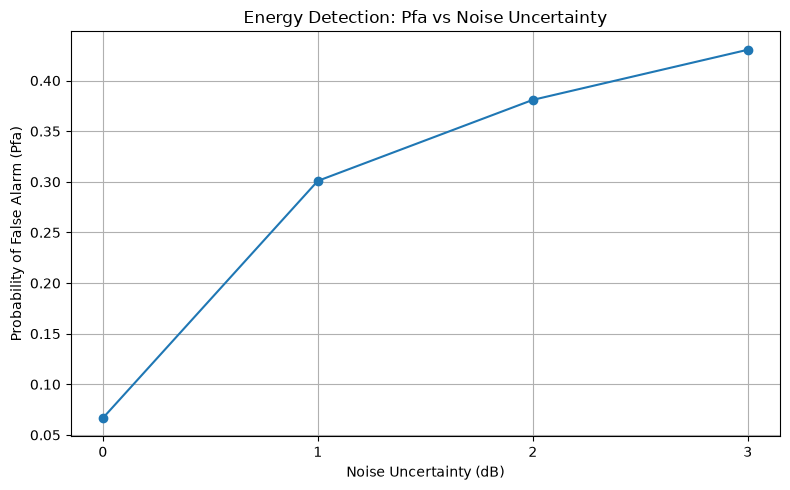

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    uncertainty_df["Uncertainty_dB"],
    uncertainty_df["Pfa"],
    marker="o"
)

plt.xlabel("Noise Uncertainty (dB)")
plt.ylabel("Probability of False Alarm (Pfa)")
plt.title("Energy Detection: Pfa vs Noise Uncertainty")
plt.xticks(uncertainty_levels)
plt.grid(True)
plt.tight_layout()
plt.savefig("ed_pfa_vs_uncertainty.png", dpi=300)
plt.show()

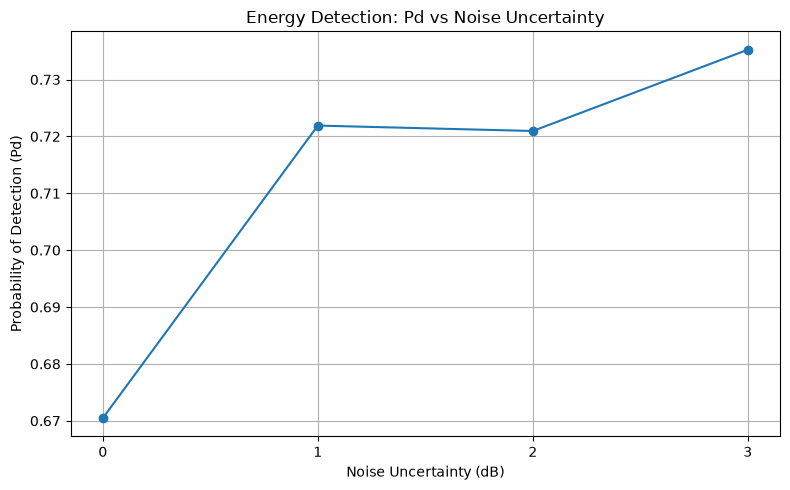

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    uncertainty_df["Uncertainty_dB"],
    uncertainty_df["Pd"],
    marker="o"
)

plt.xlabel("Noise Uncertainty (dB)")
plt.ylabel("Probability of Detection (Pd)")
plt.title("Energy Detection: Pd vs Noise Uncertainty")
plt.xticks(uncertainty_levels)
plt.grid(True)
plt.tight_layout()
plt.savefig("ed_pd_vs_uncertainty.png", dpi=300)
plt.show()

In [13]:
from scipy.stats import skew, kurtosis
from sklearn.metrics import accuracy_score, confusion_matrix

def extract_energy_features(signal):
    energy = np.mean(np.abs(signal)**2)
    log_energy = np.log10(energy + 1e-12)
    rms = np.sqrt(energy)

    return [energy, log_energy, rms]


def extract_statistical_features(signal):
    real_part = signal.real
    imag_part = signal.imag
    magnitude = np.abs(signal)

    return [
        np.mean(real_part),
        np.mean(imag_part),
        np.std(real_part),
        np.std(imag_part),
        skew(magnitude),
        kurtosis(magnitude)
    ]


def extract_frequency_features(signal):
    spectrum = np.fft.fft(signal)
    power_spectrum = np.abs(spectrum)**2

    total_power = np.sum(power_spectrum) + 1e-12
    normalized_power = power_spectrum / total_power

    frequencies = np.fft.fftfreq(len(signal))
    abs_frequencies = np.abs(frequencies)

    centroid = np.sum(abs_frequencies * normalized_power)

    bandwidth = np.sqrt(
        np.sum(
            ((abs_frequencies - centroid)**2) * normalized_power
        )
    )

    entropy = -np.sum(
        normalized_power * np.log2(normalized_power + 1e-12)
    )

    peak_power = np.max(normalized_power)

    return [centroid, bandwidth, entropy, peak_power]

In [15]:
print("Energy features:", len(extract_energy_features(X_iq[0])))
print("Statistical features:", len(extract_statistical_features(X_iq[0])))
print("Frequency features:", len(extract_frequency_features(X_iq[0])))

Energy features: 3
Statistical features: 6
Frequency features: 4


In [20]:
import joblib
import numpy as np

lr_model = joblib.load("logistic_regression_model.pkl")

lr_threshold = float(
    np.load("logistic_regression_threshold.npy")
)

print("Model loaded:", lr_model)
print("Threshold:", lr_threshold)
print("Scaler features:", scaler.n_features_in_)

Model loaded: LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
Threshold: 0.7525429211626531
Scaler features: 13


In [21]:
import joblib

scaler = joblib.load("logistic_regression_scaler.pkl")

print("Original scaler loaded successfully.")
print("Number of features:", scaler.n_features_in_)
print("LR model available:", "lr_model" in globals())
print("LR threshold available:", "lr_threshold" in globals())
print("Scaler available:", "scaler" in globals())

Original scaler loaded successfully.
Number of features: 13
LR model available: True
LR threshold available: True
Scaler available: True


In [23]:
lr_uncertainty_results = []

for uncertainty in uncertainty_levels:

    dataset = uncertainty_datasets[uncertainty]

    X_unc = dataset["X"]
    y_unc = dataset["y"]

    # Extract test observations
    X_test_unc = X_unc[test_idx]
    y_test_unc = y_unc[test_idx]

    # Extract the original 13 features
    X_test_features = np.array([
        extract_energy_features(x)
        + extract_statistical_features(x)
        + extract_frequency_features(x)
        for x in X_test_unc
    ])

    # Apply original training-fitted scaler
    X_test_scaled = scaler.transform(X_test_features)

    # Predict probabilities using trained LR model
    y_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

    # Apply original validation-calibrated threshold
    y_pred = (y_prob > lr_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_unc,
        y_pred,
        labels=[0, 1]
    ).ravel()

    lr_uncertainty_results.append({
        "Uncertainty_dB": uncertainty,
        "Accuracy": accuracy_score(y_test_unc, y_pred),
        "Pd": tp / (tp + fn),
        "Pfa": fp / (fp + tn),
        "Pm": fn / (fn + tp)
    })

lr_uncertainty_df = pd.DataFrame(lr_uncertainty_results)

print(lr_uncertainty_df.round(4))
lr_uncertainty_df.to_csv(
    "logistic_regression_noise_uncertainty.csv",
    index=False
)

   Uncertainty_dB  Accuracy      Pd     Pfa      Pm
0               0    0.6748  0.3971  0.0476  0.6029
1               1    0.6752  0.3886  0.0381  0.6114
2               2    0.6743  0.4114  0.0629  0.5886
3               3    0.6776  0.4210  0.0657  0.5790


In [24]:
import joblib
import numpy as np

rf_model = joblib.load("random_forest_model.pkl")

rf_threshold = float(
    np.load("random_forest_threshold.npy")
)

print("Random Forest model loaded:", rf_model)
print("Original threshold:", rf_threshold)
print("Feature count:", rf_model.n_features_in_)

Random Forest model loaded: RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)
Original threshold: 0.62
Feature count: 13


In [25]:
print("Model available:", "rf_model" in globals())
print("Threshold available:", "rf_threshold" in globals())
print("Feature count:", rf_model.n_features_in_)
print("Threshold:", rf_threshold)

Model available: True
Threshold available: True
Feature count: 13
Threshold: 0.62


In [26]:
rf_uncertainty_results = []

for uncertainty in uncertainty_levels:

    dataset = uncertainty_datasets[uncertainty]

    X_unc = dataset["X"]
    y_unc = dataset["y"]

    X_test_unc = X_unc[test_idx]
    y_test_unc = y_unc[test_idx]

    # Extract original 13 features
    X_test_features = np.array([
        extract_energy_features(x)
        + extract_statistical_features(x)
        + extract_frequency_features(x)
        for x in X_test_unc
    ])

    # Random Forest does not require feature scaling
    y_prob = rf_model.predict_proba(X_test_features)[:, 1]

    # Apply original calibrated threshold
    y_pred = (y_prob > rf_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_unc,
        y_pred,
        labels=[0, 1]
    ).ravel()

    rf_uncertainty_results.append({
        "Uncertainty_dB": uncertainty,
        "Accuracy": accuracy_score(y_test_unc, y_pred),
        "Pd": tp / (tp + fn),
        "Pfa": fp / (fp + tn),
        "Pm": fn / (fn + tp)
    })

rf_uncertainty_df = pd.DataFrame(rf_uncertainty_results)

print(rf_uncertainty_df.round(4))
rf_uncertainty_df.to_csv(
    "random_forest_noise_uncertainty.csv",
    index=False
)

   Uncertainty_dB  Accuracy      Pd     Pfa      Pm
0               0    0.8195  0.6952  0.0562  0.3048
1               1    0.7605  0.6733  0.1524  0.3267
2               2    0.6852  0.6429  0.2724  0.3571
3               3    0.6524  0.6457  0.3410  0.3543


In [27]:
# Add model identifiers
ed_comparison = uncertainty_df.copy()
ed_comparison["Model"] = "Energy Detection"

lr_comparison = lr_uncertainty_df.copy()
lr_comparison["Model"] = "Logistic Regression"

rf_comparison = rf_uncertainty_df.copy()
rf_comparison["Model"] = "Random Forest"

# Combine all results
noise_uncertainty_comparison = pd.concat(
    [
        ed_comparison,
        lr_comparison,
        rf_comparison
    ],
    ignore_index=True
)

# Arrange columns
noise_uncertainty_comparison = (
    noise_uncertainty_comparison[
        [
            "Model",
            "Uncertainty_dB",
            "Accuracy",
            "Pd",
            "Pfa",
            "Pm"
        ]
    ]
)

print(noise_uncertainty_comparison.round(4))

                  Model  Uncertainty_dB  Accuracy      Pd     Pfa      Pm
0      Energy Detection               0    0.8019  0.6705  0.0667  0.3295
1      Energy Detection               1    0.7105  0.7219  0.3010  0.2781
2      Energy Detection               2    0.6700  0.7210  0.3810  0.2790
3      Energy Detection               3    0.6524  0.7352  0.4305  0.2648
4   Logistic Regression               0    0.6748  0.3971  0.0476  0.6029
5   Logistic Regression               1    0.6752  0.3886  0.0381  0.6114
6   Logistic Regression               2    0.6743  0.4114  0.0629  0.5886
7   Logistic Regression               3    0.6776  0.4210  0.0657  0.5790
8         Random Forest               0    0.8195  0.6952  0.0562  0.3048
9         Random Forest               1    0.7605  0.6733  0.1524  0.3267
10        Random Forest               2    0.6852  0.6429  0.2724  0.3571
11        Random Forest               3    0.6524  0.6457  0.3410  0.3543


In [28]:
noise_uncertainty_comparison.to_csv(
    "noise_uncertainty_model_comparison.csv",
    index=False
)

print("Noise uncertainty comparison saved.")

Noise uncertainty comparison saved.


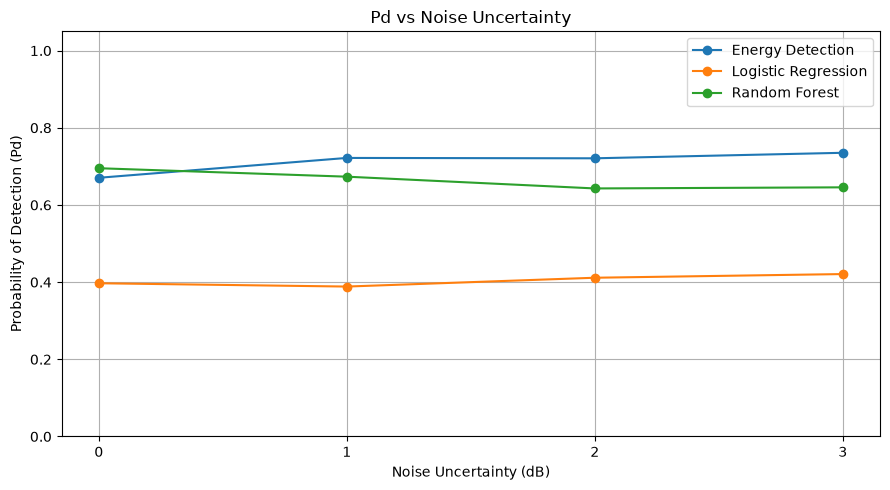

In [29]:
plt.figure(figsize=(9, 5))

for model in noise_uncertainty_comparison["Model"].unique():
    data = noise_uncertainty_comparison[
        noise_uncertainty_comparison["Model"] == model
    ]

    plt.plot(
        data["Uncertainty_dB"],
        data["Pd"],
        marker="o",
        label=model
    )

plt.xlabel("Noise Uncertainty (dB)")
plt.ylabel("Probability of Detection (Pd)")
plt.title("Pd vs Noise Uncertainty")
plt.xticks(uncertainty_levels)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("comparison_pd_noise_uncertainty.png", dpi=300)
plt.show()

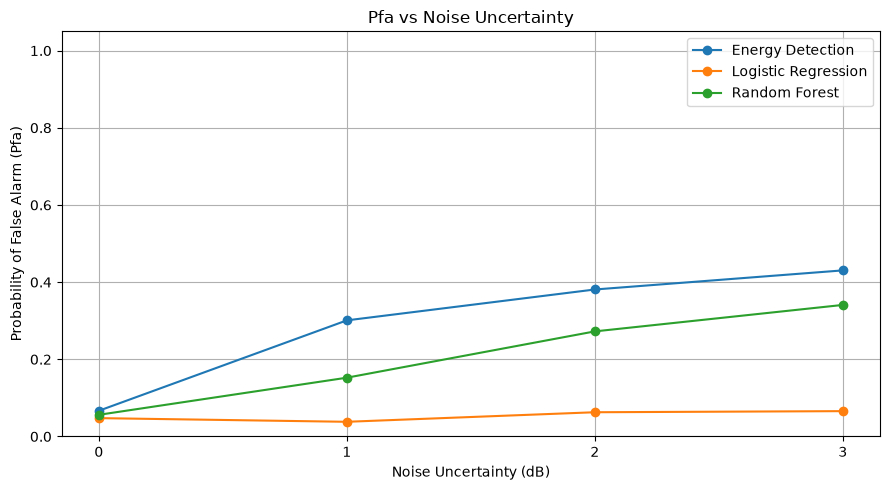

In [30]:
plt.figure(figsize=(9, 5))

for model in noise_uncertainty_comparison["Model"].unique():
    data = noise_uncertainty_comparison[
        noise_uncertainty_comparison["Model"] == model
    ]

    plt.plot(
        data["Uncertainty_dB"],
        data["Pfa"],
        marker="o",
        label=model
    )

plt.xlabel("Noise Uncertainty (dB)")
plt.ylabel("Probability of False Alarm (Pfa)")
plt.title("Pfa vs Noise Uncertainty")
plt.xticks(uncertainty_levels)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("comparison_pfa_noise_uncertainty.png", dpi=300)
plt.show()

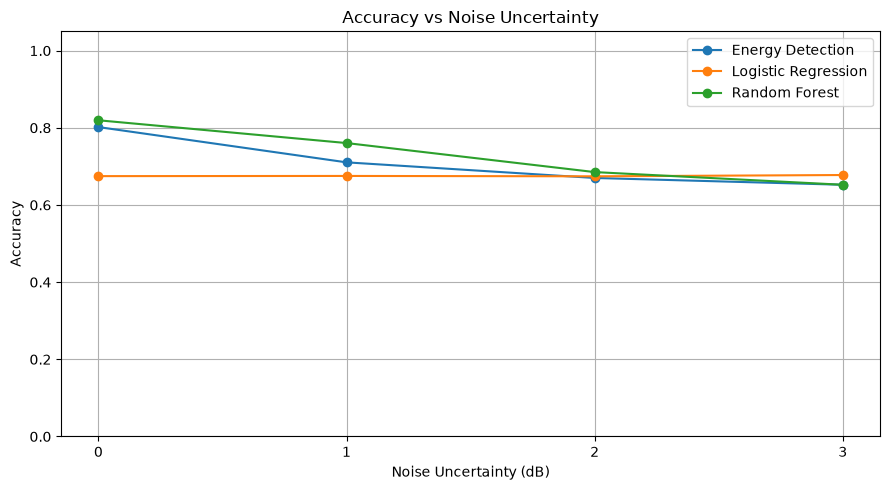

In [31]:
plt.figure(figsize=(9, 5))

for model in noise_uncertainty_comparison["Model"].unique():
    data = noise_uncertainty_comparison[
        noise_uncertainty_comparison["Model"] == model
    ]

    plt.plot(
        data["Uncertainty_dB"],
        data["Accuracy"],
        marker="o",
        label=model
    )

plt.xlabel("Noise Uncertainty (dB)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Noise Uncertainty")
plt.xticks(uncertainty_levels)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("comparison_accuracy_noise_uncertainty.png", dpi=300)
plt.show()